In [1]:
%load_ext autoreload
%autoreload 2

from kontext.visualization import get_figs,space_plot,space_plot_mask,get_proportions,plot_proportions,heatmap_proportions,plot_cluster_ccc_score,umap_plot,plot_ct_pair_across_samples,plot_region_distribution,pie_region
from kontext.data import load_adata,merge_adatas,preprocess_adata,load_and_preprocess_adata
from kontext.new_context_class import NContext
from kontext.utils import me_correlation, get_LR_pairs, pca_of_mat,get_purity_vector_per_cluster


from umap.umap_ import UMAP
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#fcf8f500'
plt.rcParams['axes.facecolor'] = '#fcf8f500'

from itables import init_notebook_mode
init_notebook_mode(all_interactive=True)



In [2]:
dataset = 'CARDIO'
samples = ['sham_S1','sham_S2',
            'cryo7D_S1','cryo7D_S2','cryo7D_S3',        
            'cryo28D_S1','cryo28D_S2','cryo28D_S3',
            ]


In [3]:
no_preprocessing = {'preprocessing':None}
preprocessing = {'preprocessing':'xenium'}
embedding = {"sigma_e":1, "snn":20, 'alpha':1}
clustering = {'clustering':'gmm','seed':0,'n_clusters':8}
niche,me,communication=True,True,True
# niche,me,communication=False,False,False



adatas = {}
for k in samples:
    print(k)
    adata = load_and_preprocess_adata({'dataset':'CARDIO','sample':k},preprocessing_params=no_preprocessing)
    adatas[k] = adata
adata_ = merge_adatas(adatas)
adata_.layers['counts'] = adata_.X
adata_ = preprocess_adata(adata_,**preprocessing)

adatas = {}
for k in samples:
    print(k)
    adata = adata_[adata_.obs['sample']==k].copy()
    adata.uns = adata_.uns.copy()
    adata.uns['data']['sample']=k
    context = NContext(**embedding,verbose=False)
    adata = context.weights(adata)
    context.fit(adata,add_layer=True)
    context.smooth_and_pca(adata, "wc", "C",add_layer=True)


    if niche:
        context.niche_context(adata, matrix="C", cell_type_key="global_cell_type",verbose=False)
        context.niche_context(adata, matrix="C", cell_type_key="cell_type",verbose=False)
    if me:
        me_correlation(adata, layer_C="C")
    # if communication:
    #     groups='main_cell_type'
    #     pairs = get_LR_pairs(adata,verbose=False)
    #     communication_type = 'exocrine'
    #     context.LR_scores(adata,communication_type=communication_type,groups=groups)
    #     communication_type = 'groups'
    #     context.LR_scores(adata,communication_type=communication_type,groups=groups)

    adatas[k] = adata 


adata_ = merge_adatas(adatas,block_diag_keys=['w','ws','wc'])

# if communication:
#     groups='main_cell_type'
#     pairs = get_LR_pairs(adata_,verbose=False)
#     communication_type = 'all'
#     context.LR_scores(adata_,communication_type=communication_type,groups=groups)
#     communication_type = 'exocrine'
#     context.LR_scores(adata_,communication_type=communication_type,groups=groups)
#     communication_type = 'groups'
#     context.LR_scores(adata_,communication_type=communication_type,groups=groups)






adata_.uns['data'] = {'dataset':'CARDIO','sample':'all','pp_str':'large2svg_joint'}
context = NContext(**embedding,verbose=True)
print('clustering')
context.clustering_of_merged_adata(adata_,**clustering)




sham_S1
sham_S2
cryo7D_S1
cryo7D_S2
cryo7D_S3
cryo28D_S1
cryo28D_S2
cryo28D_S3
sham_S1
sham_S2
cryo7D_S1
cryo7D_S2
cryo7D_S3
cryo28D_S1
cryo28D_S2
cryo28D_S3
clustering
pca of merged adata
clustering of merged adata
[Errno 2] No such file or directory: '/pasteur/appa/scratch/aozierla/CARDIO/all/large2svg_joint/context/clustering/snn20_se1_nPC50_a1_gmm_seed0_n_clusters8.csv'
/pasteur/appa/scratch/aozierla/CARDIO/all/large2svg_joint/context/clustering/snn20_se1_nPC50_a1_gmm_seed0_n_clusters8.csv
not loaded, computing clustering


In [ ]:

clustering_mapping = {
    3:0,
    1:1,
    2:2,
    4:6,
    0:7,
    7:4,
    5:3,
    6:5,}


adata_.obs['clustering_sorted'] = adata_.obs['clustering'].map(clustering_mapping)
adata_.obs['clustering_sorted'] = adata_.obs['clustering_sorted'].astype('category').cat.set_categories(sorted(clustering_mapping.keys()))


print(adata_.obs['main_cell_type'].nunique())
clustering_colors = [
    "#0072B2","#D55E00","#009E73","#CC79A7",
    "#E69F00","#56B4E9","#F0E442","#4E1A1A",]
cell_type_colors = [
    "#8DD3C7","#FFFFB3","#BEBADA","#FB8072",
    "#80B1D3","#FDB462","#B3DE69","#FCCDE5",
    "#D9D9D9","#BC80BD","#CCEBC5", "#FFED6F",
    "#DCD685","#D7AFAF",

    ]
time_colors = ["#d7b043","#BE4A4A","#006267",]

adata_.uns['clustering_colors'] = clustering_colors
adata_.uns['clustering_sorted_colors'] = clustering_colors
adata_.uns['main_cell_type_colors'] = cell_type_colors
adata_.uns['time_colors'] = time_colors


12


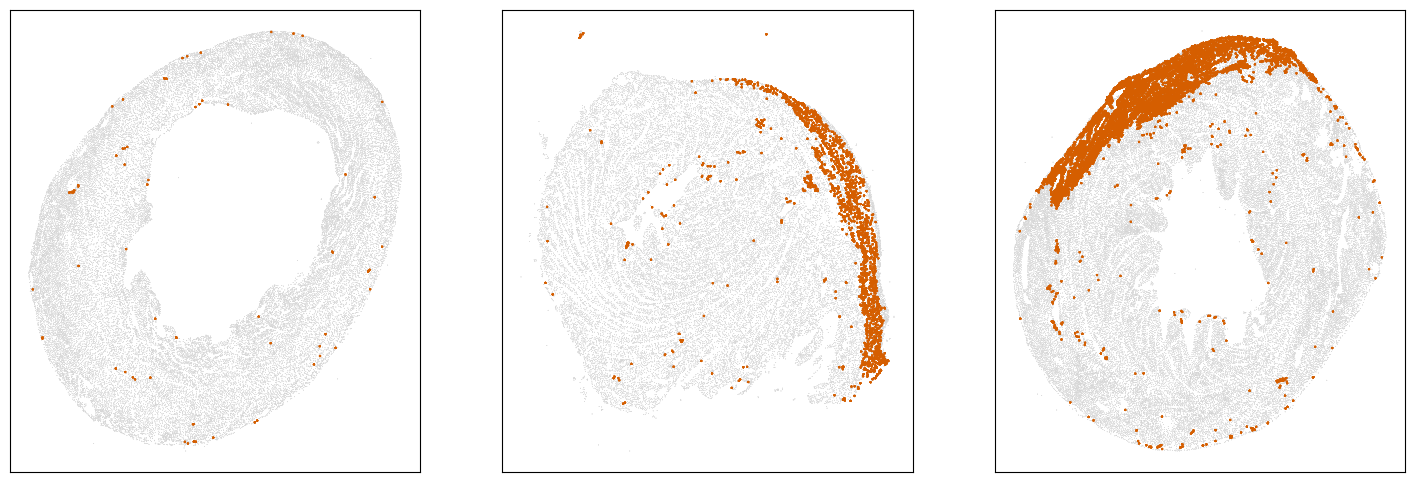

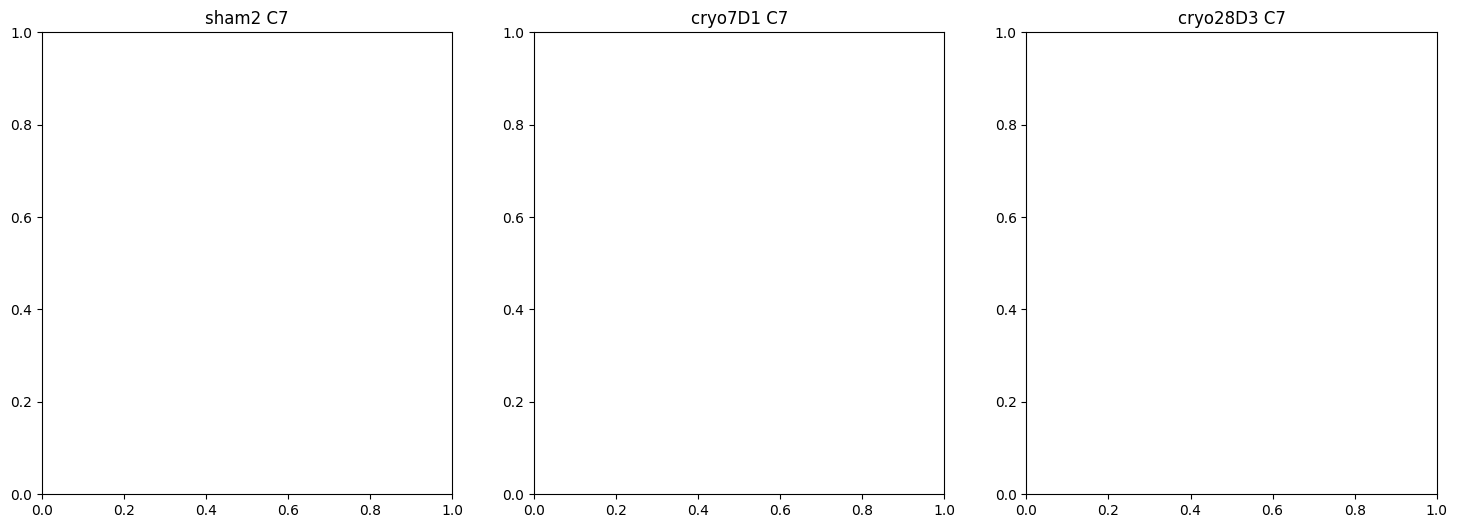

In [5]:
color = 'clustering_sorted'
group = 1 
clusters = adata_.obs[color].sort_values().unique()

samples_2a = ['sham_S2',
            'cryo7D_S1',        
            'cryo28D_S3',
            ]



fig_png,axes_png = get_figs(len(samples_2a))
fig_pdf,axes_pdf = get_figs(len(samples_2a))
for i,sample in enumerate(samples_2a):
    ax_png = axes_png[i]
    ax_pdf = axes_pdf[i]
    adata = adata_[adata_.obs['sample']==sample]
    for j in clusters:
        mask = space_plot_mask(adata,color,group,ax=ax_png,snm=1,sm=10)
        ax_png.get_legend().remove()
        ax_png.set_xlabel("")
        ax_png.set_ylabel("")
        ax_png.set_title("")

        ax_pdf.set_title(f"{sample.replace('_S','')} C{j}")

        # ax.get_legend().remove()
plt.show()
# fig_png.savefig('kontext_project/figures/cryo/cryo_2a_space_plot_injury.png')
# fig_pdf.savefig('kontext_project/figures/cryo/cryo_2a_space_plot_injury.pdf')


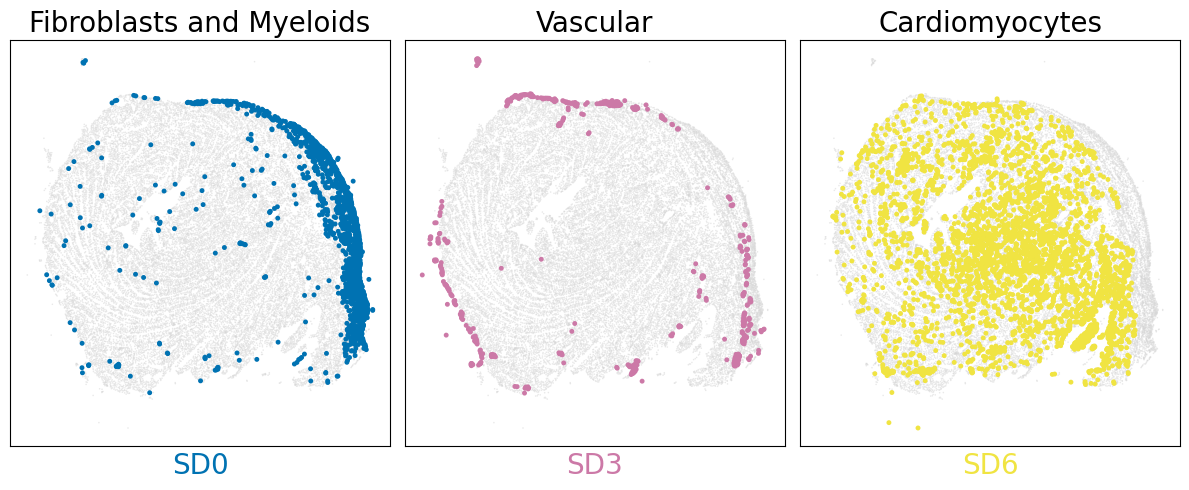

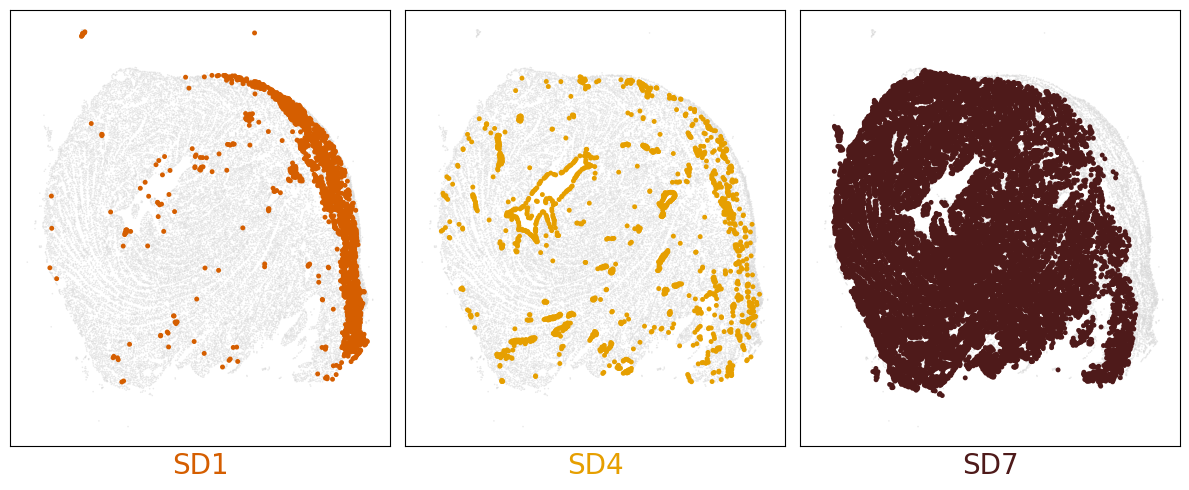

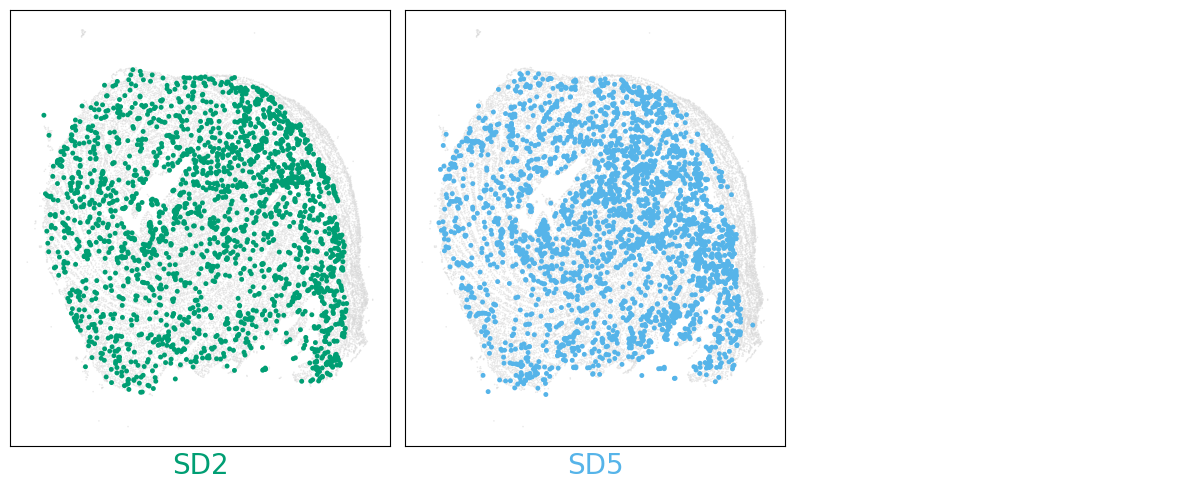

In [47]:
color = "clustering_sorted"
clusters = adata_.obs[color].sort_values().unique()
sample='cryo7D_S1'

ncols=len(clusters)


adata = adata_[adata_.obs['sample']==sample]

group_names = ['Fibroblasts and Myeloids','Vascular','Cardiomyocytes']
groups = [0,3,6],[1,4,7],[2,5,8]
for i,group in enumerate(groups):
    fig,axes = get_figs(3,4,5)
    for ax,name,domain in zip(axes,group_names,group):
        if domain == 8:
            ax.set_axis_off()
            continue

        mask = space_plot_mask(adata,color,domain,ax=ax,snm=5,sm=50)
        ax.set_title(name if i == 0 else '',fontsize=20)        
        ax.set_xlabel(f"SD{domain}",fontsize=20,color=adata.uns[f'{color}_colors'][domain])
        ax.set_ylabel("")
        ax.get_legend().remove()

    fig.tight_layout()
plt.show()
# sample.replace('_S','').replace('sham','0D').replace('cryo','')} 
# fig.savefig('kontext_project/figures/cryo/cryo_2b_space_plot_clustering.pdf')

clustering_sorted
0     10046
1     16665
2     20163
3      7556
4     10211
5      7487
6     19146
7    170859
dtype: int64
(8, 12)


Loading ITables v2.7.3 from the init_notebook_mode cell... (need help?)


main_cell_type     Cardiomyocyte  Fibroblast  Fibrocyte  Lymphoid  Macrophage  \
clustering_sorted                                                               
0                              3        1787         49       490        2611   
1                             13       10758        155       246        1535   
2                           1247        9097        299       353        5864   
3                             39         545         14        48          43   
4                             24         648         19        73          67   
5                            109         550         32       359         182   
6                           7895        3178         64      2852         619   
7                          78693       10703        507     12212        3186   

main_cell_type     Myeloid_other  Myofibroblast  Other    vEC  vEpicardial  \
clustering_sorted                                                            
0                           2309 

/local/scratch/tmp/ipykernel_2959055/1134540048.py:63: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


Text(0.5, 0, 'Normalized proportions')

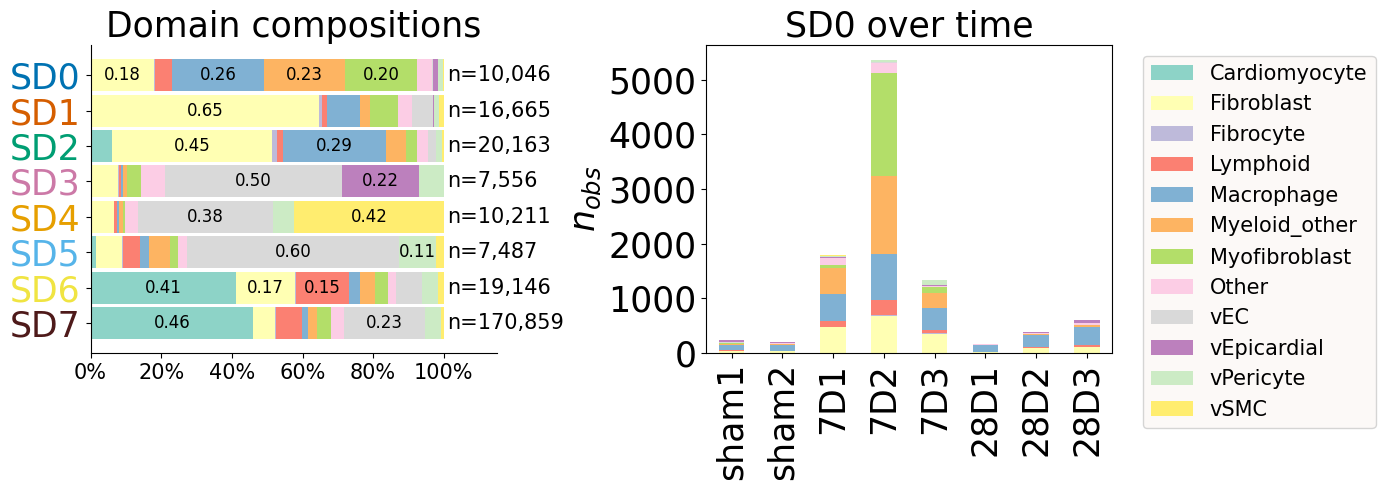

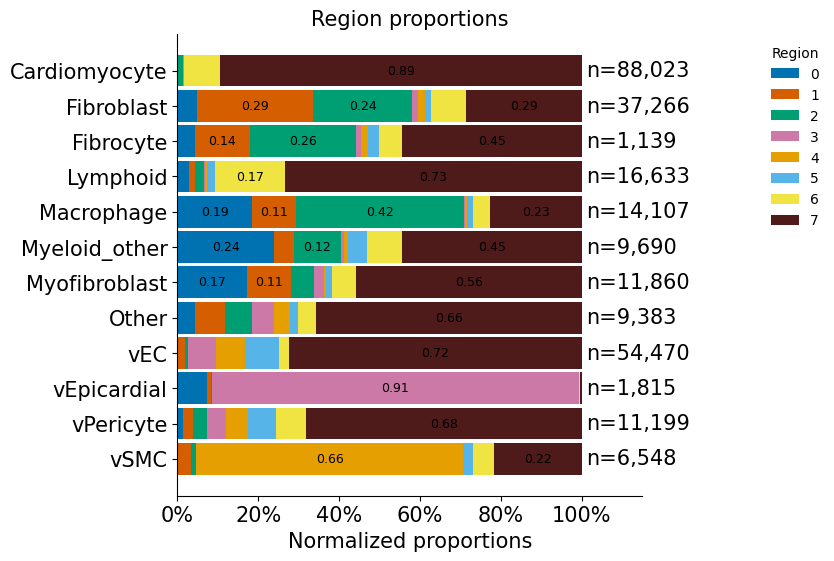

In [107]:



col1,col2 = ['clustering_sorted','main_cell_type']
fig,axes = get_figs(2,7,5)
fs = 25



ax = axes[0]
proportions1 = get_proportions(adata_,col1,col2,normalize=False)
print(proportions1.sum(1))
print(proportions1.shape)
display(proportions1)
proportions1 = get_proportions(adata_,col1,col2,normalize=False)
plot_region_distribution(proportions1,colors = adata_.uns[f'{col2}_colors'] ,ax=ax,fontsize=12,format_value='.2f',threshold=.1,percentage=True)
ax.get_legend().remove()
for tl in ax.get_yticklabels():
    c = int(tl._text)
    tl.set_color(adata_.uns[f'{col1}_colors'][c])
ax.set_yticklabels([f'SD{tick._text}' for tick in ax.get_yticklabels()], rotation='horizontal', fontsize=fs) 
ax.set_xticklabels([f'{xtick._text}' for xtick in ax.get_xticklabels()], rotation='horizontal', fontsize=15) 

# ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=fs) 
ax.set_title('Domain compositions',fontsize=fs)
# ax.set_ylabel('Proportions',fontsize=fs)
ax.set_xlabel('',fontsize=fs)



# fig.tight_layout()
# fig.savefig('kontext_project/figures/cryo/cryo_2c_cluster_proportions.pdf',bbox_inches='tight')



ax = axes[1]
cols = (['sample','main_cell_type'],)#,['time','main_cell_type'])#['sample','global_cell_type'])
for cluster in range(8):
    if cluster in [0]:
        adata = adata_[adata_.obs['clustering_sorted']==cluster]
        for col1,col2 in cols:

            # fig,axes = get_figs(1,6,5)
            proportions2 = get_proportions(adata,col1,col2,normalize='index')
            proportions2 = get_proportions(adata,col1,col2,normalize=False)
            ax.set_title(f'cluster {cluster}')
            plot_proportions(proportions2,ax=ax,colors =adata_.uns[f'{col2}_colors'])
            ax.set_xticklabels([xtick._text.replace('_S','').replace('cryo','')#.replace('sham','0D') 
                                for xtick in ax.get_xticklabels()], rotation='vertical', fontsize=fs) 
            ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=fs) 
            ax.set_title('SD0 over time',fontsize=fs)
            ax.set_ylabel('$n_{obs}$',fontsize=fs)
            ax.set_xlabel('',fontsize=fs)
            legend = ax.legend(fontsize=15,bbox_to_anchor=(1.05, 1),loc='upper left')
fig.tight_layout()




# fig.savefig('kontext_project/figures/cryo/cryo_2c_proportions.pdf',bbox_inches='tight', bbox_extra_artists=(legend,))



barcode
aacbbemf-1-sham_S1-sham_S1         -3.925410
aacdjnha-1-sham_S1-sham_S1         -6.643856
aacjobhm-1-sham_S1-sham_S1         -4.604486
aaddfjah-1-sham_S1-sham_S1         -6.643856
aadhajhn-1-sham_S1-sham_S1         -2.480775
                                      ...   
ohfpnpeb-1-cryo28D_S3-cryo28D_S3    1.816726
ohgkipal-1-cryo28D_S3-cryo28D_S3   -6.643856
ohhbajgp-1-cryo28D_S3-cryo28D_S3    1.221300
ohplcego-1-cryo28D_S3-cryo28D_S3   -6.643856
oipbncji-1-cryo28D_S3-cryo28D_S3    5.624623
Name: log_LR_all, Length: 262133, dtype: float64


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/visualization.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/visualization.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.


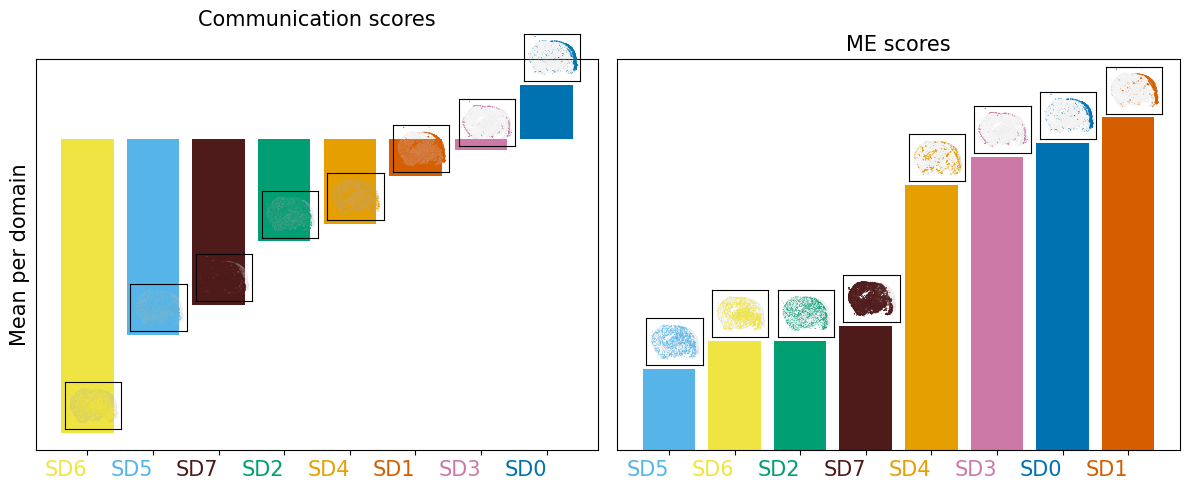

In [137]:
fig, axes = get_figs(2, 6, 5)

from kontext.utils import lr_normalize,lr_moments,lr_availability,lr_moments,lr_score,lr_aggregate,lr_cell_score,lr_log

mode = 'mean'
pairs = get_LR_pairs(adata_, organism='mouse', verbose=False)
lr_normalize(adata_, pairs)
lr_moments(adata_, 'X_lr')
lr_availability(adata_, None)
lr_moments(adata_, 'A_all')
# lr_moments(adata_, 'P_all')
lr_cell_score(adata_, 'all', mode=mode, col='LR_A_all',src='A')  
# lr_cell_score(adata_, 'all', mode=mode, col='LR_P_all',src='P')  

adata_.obs[f'log_LR_all'] = lr_log(adata_.obs[f'LR_all'])
print(adata_.obs[f'log_LR_all'])


ax = plot_cluster_ccc_score(adata_, 'clustering_sorted', 'log_LR_all','sample','cryo7D_S1', ax=axes[0], insersion=(.10, .12))
# ax.axhline(1, ls='--', lw=.8, c='grey')
ax.set_title('Communication scores', fontsize=15); ax.set_ylabel('Mean per domain', fontsize=15); ax.set_xlabel(''); ax.set_yticks([])
ax.set_xticklabels([f'SD{t._text}' for t in ax.get_xticklabels()], rotation='horizontal', fontsize=15)
ax = plot_cluster_ccc_score(adata_, 'clustering_sorted', 'me_correlation', 'sample','cryo7D_S1', ax=axes[1], insersion=(.10, .12))
ax.set_title('ME scores', fontsize=15); ax.set_ylabel(''); ax.set_xlabel(''); ax.set_yticks([])
ax.set_xticklabels([f'SD{t._text}' for t in ax.get_xticklabels()], rotation='horizontal', fontsize=15)
fig.tight_layout(); plt.show()

# fig, axes = get_figs(2, 6, 5)
# axes[0] = plot_cluster_ccc_score(adata_, 'clustering_sorted', 'LR_P_all','sample','cryo7D_S1', ax=axes[0], insersion=(.10, .12))
# axes[1] = plot_cluster_ccc_score(adata_, 'clustering_sorted', 'LR_A_all','sample','cryo7D_S1', ax=axes[1], insersion=(.10, .12))

#
# fig.savefig('kontext_project/figures/cryo/cryo_2e_communication_and_ME.png')

In [132]:
adata_.obs['LR_A_all'],adata_.obs['LR_P_all'],adata_.obs['LR_A_all']==adata_.obs['LR_P_all']

(barcode
 aacbbemf-1-sham_S1-sham_S1           0.065816
 aacdjnha-1-sham_S1-sham_S1           0.000000
 aacjobhm-1-sham_S1-sham_S1           0.041107
 aaddfjah-1-sham_S1-sham_S1           0.000000
 aadhajhn-1-sham_S1-sham_S1           0.179148
                                       ...    
 ohfpnpeb-1-cryo28D_S3-cryo28D_S3     3.522808
 ohgkipal-1-cryo28D_S3-cryo28D_S3     0.000000
 ohhbajgp-1-cryo28D_S3-cryo28D_S3     2.331568
 ohplcego-1-cryo28D_S3-cryo28D_S3     0.000000
 oipbncji-1-cryo28D_S3-cryo28D_S3    49.337860
 Name: LR_A_all, Length: 262133, dtype: float32,
 barcode
 aacbbemf-1-sham_S1-sham_S1           0.065816
 aacdjnha-1-sham_S1-sham_S1           0.000000
 aacjobhm-1-sham_S1-sham_S1           0.041107
 aaddfjah-1-sham_S1-sham_S1           0.000000
 aadhajhn-1-sham_S1-sham_S1           0.179148
                                       ...    
 ohfpnpeb-1-cryo28D_S3-cryo28D_S3     3.522808
 ohgkipal-1-cryo28D_S3-cryo28D_S3     0.000000
 ohhbajgp-1-cryo28D_S3-cryo28D_S3     2.

In [127]:
import seaborn as sns
groups, ts, tr = 'main_cell_type', 'Fibroblast', 'Macrophage'
mode, samples_ = 'mean', ['sham_S1', 'cryo7D_S1', 'cryo28D_S1']
mode, times_ = 'mean', ['sham', 'cryo7D', 'cryo28D']  


genes = [
    'Cfh_Itgam',
    'C3_Itgam',
    'C3_C3ar1',


    'Ccl12_Ccr2',
    'Spp1_Cd44',
    'Mmp9_Cd44',
    'Ptn_Sdc1',

    'Thbs4_Cd36',
    'Thbs4_Sdc1',
    'Comp_Sdc1',

    'Bmp7_Eng',

    'Timp3_Cd44',
    'S100a4_Erbb2',

    'Timp3_Kdr',
    'Angpt2_Tie1',
]

mode = 'mean'
pairs = get_LR_pairs(adata_, organism='mouse', verbose=False)
lr_normalize(adata_, pairs)
lr_availability(adata_, None)
lr_moments(adata_, 'X_lr')
lr_moments(adata_, 'A_all')
lr_cell_score(adata_, 'all', mode=mode, col='LR_all')  
lr_moments(adata_, 'P_all')



ts, tr = 'Fibroblast', 'Macrophage'
for tx,tc in (ts, tr),(tr,ts),(ts, ts), (tr, tr): 
    # lr_moments(adata_, f'A_{tc}', om=((adata_.obs[f'm_{tc}'] > 0) & (adata_.obs['main_cell_type']==tx) ).values,r=r)
    lr_availability(adata_, tx, groups)
    lr_availability(adata_, tc, groups)
    r = {'col':groups,'value':tx}
    lr_moments(adata_, 'X_lr',r=r)
    lr_moments(adata_, f'A_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)
    lr_moments(adata_, f'P_{tc}', om=(adata_.obs[f'm_{tc}'] > 0).values,r=r)


                 sham    cryo7D   cryo28D      sham    cryo7D   cryo28D
LR                                                                     
Cfh_Itgam   -1.032809  0.488182  0.439382 -0.747586  0.552112  0.226771
C3_Itgam    -1.176934  0.650031  0.416837 -1.172074  1.069374  0.451829
C3_C3ar1    -1.280297  0.791242  0.426269 -1.052776  1.120438  0.454008
Ccl12_Ccr2  -1.277907  2.072347  0.265850 -1.221655  1.114221 -0.002603
Spp1_Cd44   -3.720966  2.887880  0.160556 -3.906315  2.280621 -0.074208
Mmp9_Cd44   -0.974582  1.261305 -0.704439 -0.911154  0.225885  0.157751
Thbs4_Cd36  -1.152104  0.390016  0.342015 -2.862478  0.521832 -0.861580
Bmp7_Eng    -2.232187 -2.076223 -0.336200  0.130447 -1.238281 -0.950383
Timp3_Cd44  -1.302907  0.785007  0.597481 -1.270453  0.588996  0.605163
Timp3_Kdr   -0.359392 -0.839871 -0.321563 -0.188153 -1.000000 -0.163827
Angpt2_Tie1  0.221615 -0.953742 -0.409619 -0.361066 -1.075067 -0.064627
                  sham    cryo7D   cryo28D      sham    cryo7D  

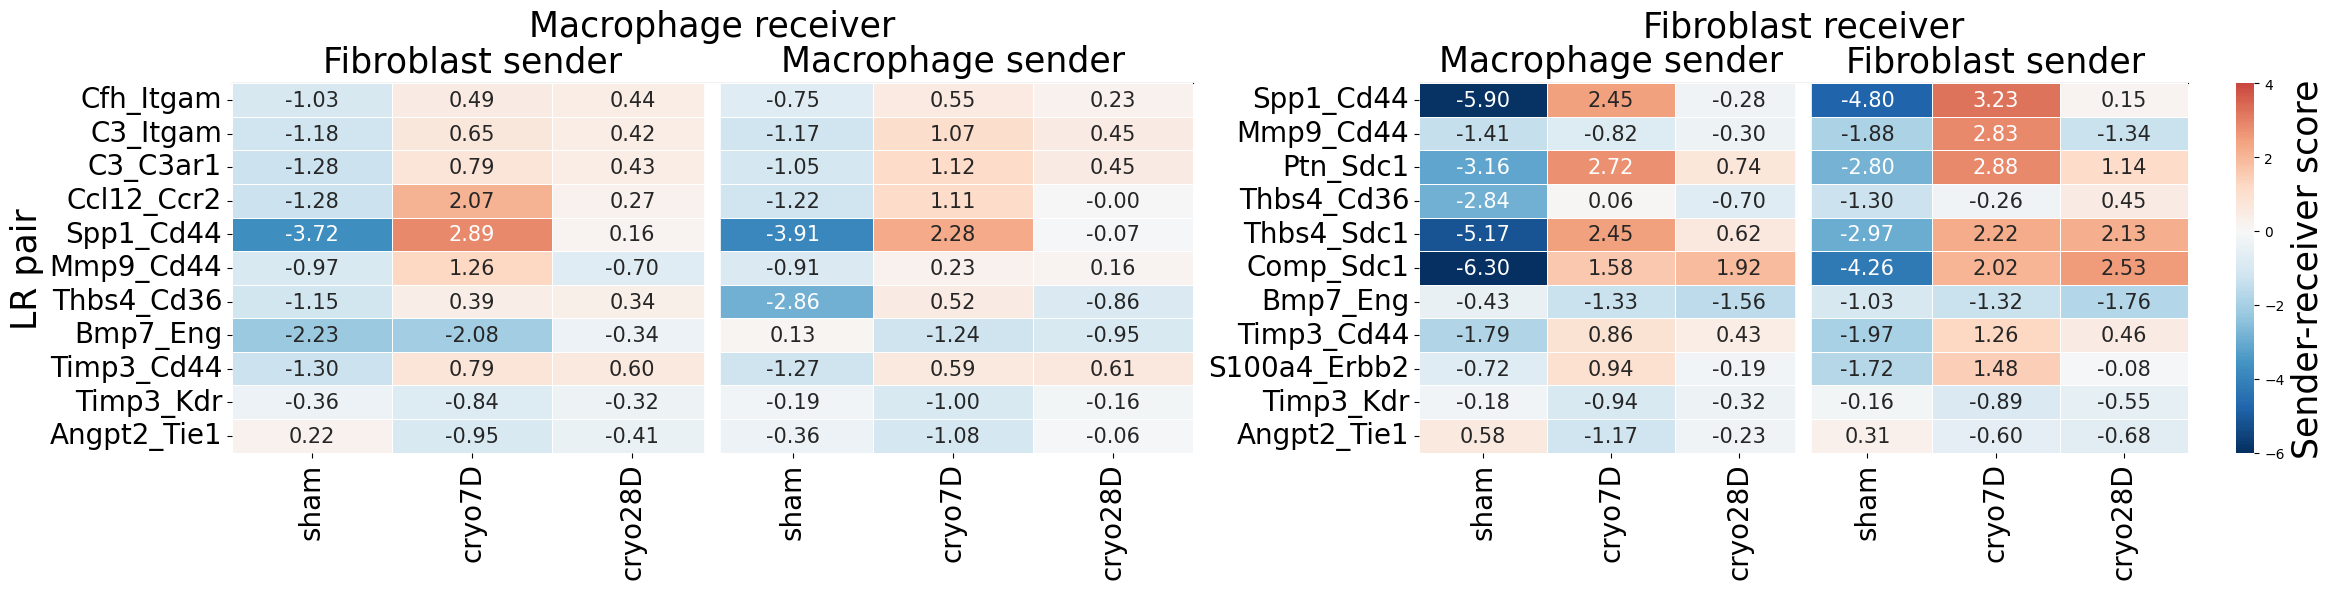

In [128]:
send_groups = [
    [(ts, tr), (tr, tr)],   # plot 1: both senders → Macrophage
    [(tr, ts), (ts, ts)],   # plot 2: both senders → Fibroblast
]

top=15
fig, axes = get_figs(len(send_groups), 12, 6)   # 2 wider plots

for i, (ax, pair_list) in enumerate(zip(axes, send_groups)):
    parts, senders = [], []
    for (s_, r_) in pair_list:
        r = {'col': groups, 'value': r_}
        S = lr_score(adata_, s_, r_, groups, mode, r=r,src='P')

        gi = pd.Index(adata_.uns['lr']['genes'])
        pos = adata_.obs_names.get_indexer(S.index)
        det = pd.Series(np.asarray((adata_.obsm['X_lr'][pos][:, gi.get_indexer(pairs.receptor)] > 0).mean(0)).ravel(), index=pairs.index)
        keep = det[det > .1].index
        T = lr_aggregate(adata_, S, s_, by='time')['all'].reindex(times_)[[g for g in genes if g in keep and g in S.columns]]

        parts.append((lr_log(T) if mode == 'mean' else T).T)
        senders.append(s_)

    merged = pd.concat(parts, axis=1)   # <-- horizontal concat: 6 columns

    label = 'Sender-receiver score' if i == 1 else ''
    cbar = (i == 1)
    print(merged)
    hm = sns.heatmap(merged, ax=ax, cmap='RdBu_r', center=0, vmin=-6, vmax=4,
                annot=True, fmt='.2f', annot_kws={'fontsize':15},
                linewidths=.5, cbar=cbar, cbar_kws={'label': label})
    if cbar:
        cbar_ax = hm.collections[0].colorbar
        cbar_ax.set_label(cbar_ax.ax.get_ylabel(), fontsize=fs)

    ax.axvline(len(parts[0].columns), color='white', lw=12)   # separator between the 2 senders

    # sender names above the time labels (optional)
    sec = ax.secondary_xaxis('top')
    sec.set_xticks([1.5, len(parts[0].columns) + 1.5])
    sec.set_xticklabels([f'{s} sender' for s in senders], fontsize=25)
    sec.tick_params(length=0)

    ax.set_title(f'{pair_list[0][1]} receiver', fontsize=25)
    ax.set_xlabel('')
    if i == 0:
        ax.set_ylabel('LR pair', fontsize=25)
    else:
        ax.set_ylabel('')
    ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=20)
    ax.set_xticklabels(ax.get_xticklabels(), rotation='vertical', fontsize=20)

fig.tight_layout()
plt.show()

# fig.savefig('kontext_project/figures/cryo/cryo_2g_FB_macro_communication.pdf')



Fibroblast Macrophage
Index(['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts',
       'control_probe_counts', 'control_codeword_counts',
       'unassigned_codeword_counts', 'deprecated_codeword_counts',
       'total_counts', 'cell_area', 'nucleus_area', 'cell_type',
       'global_cell_type', 'time', 'main_cell_type', 'sample',
       'niche_global_cell_type_B', 'niche_global_cell_type_CM',
       'niche_global_cell_type_DC', 'niche_global_cell_type_FB',
       'niche_global_cell_type_FBmyo', 'niche_global_cell_type_Fibrocytes',
       'niche_global_cell_type_ILC2', 'niche_global_cell_type_MAIT',
       'niche_global_cell_type_Macro', 'niche_global_cell_type_Mast',
       'niche_global_cell_type_NK', 'niche_global_cell_type_NM',
       'niche_global_cell_type_Neutrophil', 'niche_global_cell_type_Schwann',
       'niche_global_cell_type_T', 'niche_global_cell_type_Treg',
       'niche_global_cell_type_mo', 'niche_global_cell_type_vEC',
       'niche_global_cell_type_vEpicard

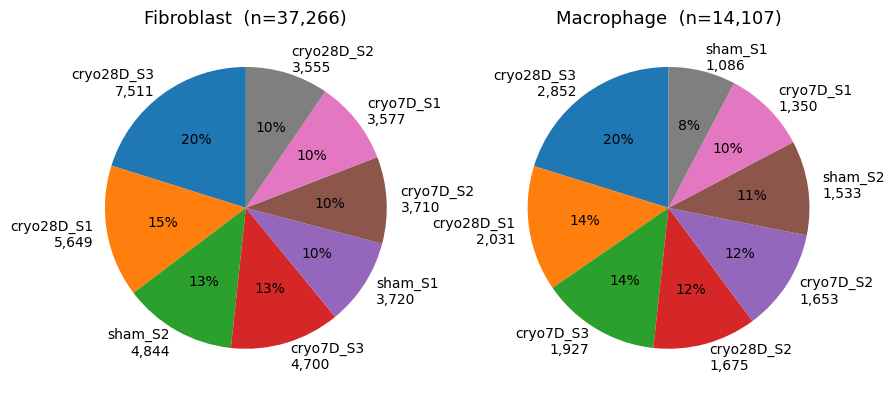

In [22]:

print(ts,tr)
print(adata.obs.columns)
fig, axes = get_figs(2, 5, 5)
for ax, t in zip(axes, [ts, tr]): pie_region(adata_, t, f'sample', 'main_cell_type', ax=ax)

In [27]:
adata1s = {}
purity = {}
for cluster in adata_.obs['clustering_sorted'].unique():
    # adata1 = adata_[adata_.obs['clustering'].isin(cluster)]

    adata1 = adata_[adata_.obs['clustering_sorted']==cluster]
    for layer in 'XCE':
        print(layer, cluster,end=' ')
        mat = adata1.X if layer == 'X' else adata1.layers[layer]  if layer in 'CE' else adata1.obsm[f'niche_global_cell_type'] if layer == 'N' else adata1.obsm[f'niche_cell_type']
        print(mat.shape)
        n_comps = 10 if layer in 'NM' else 50
        pca_of_mat(adata1, mat, n_comps=n_comps, key=f"{layer}{cluster}")
        pca = adata1.obsm[f'{layer}{cluster}_pca']
        adata1.obsm[f'{layer}{cluster}_umap'] = UMAP(n_components=2).fit_transform(pca)


    # for layer in 'XCE':#EN':
        print('purity')
        ks, cp = get_purity_vector_per_cluster(
            adata1.obsm[f'{layer}{cluster}_pca'],
            adata1.obs['time'].values,
            adata1.obs['clustering'].values,
        )
        purity[f'{layer}{cluster}'] = {'ks': ks, 'cluster_purities': cp}
    adata1s[f'{cluster}'] = adata1


X 7 (170859, 540)


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/utils.py:333: ImplicitModificationWarning: Setting element `.obsm['X7_pca']` of view, initializing view as actual.


purity
C 7 (170859, 540)
purity
E 7 (170859, 540)
purity
X 6 (19146, 540)


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/utils.py:333: ImplicitModificationWarning: Setting element `.obsm['X6_pca']` of view, initializing view as actual.


purity
C 6 (19146, 540)
purity
E 6 (19146, 540)
purity
X 0 (10046, 540)


...

purity
C 1 (16665, 540)
purity
E 1 (16665, 540)
purity
X 4 (10211, 540)


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/utils.py:333: ImplicitModificationWarning: Setting element `.obsm['X4_pca']` of view, initializing view as actual.


purity
C 4 (10211, 540)
purity
E 4 (10211, 540)
purity
X 3 (7556, 540)


/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/src/kontext/utils.py:333: ImplicitModificationWarning: Setting element `.obsm['X3_pca']` of view, initializing view as actual.


purity
C 3 (7556, 540)
purity
E 3 (7556, 540)
purity


/local/scratch/tmp/ipykernel_2544933/2846096876.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
/local/scratch/tmp/ipykernel_2544933/2846096876.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


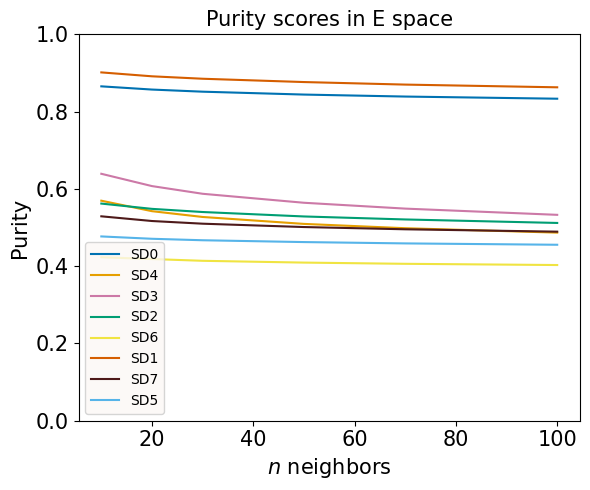

In [28]:
layers = 'E'
# for i, layer in enumerate('XCEN'):
for i, layer in enumerate(layers):
    fig, ax = get_figs(1,6,5)
    # if isinstance(axes,np.ndarray):
    #     ax = axes[i]
    # else:
    #     ax = axes
    for cluster in adata_.obs['clustering'].unique():
        key = f'{layer}{cluster}'
        if key in purity:
            ks = purity[key]['ks']
            # umap_plot(adata,color='time',umap_key=f'{layer}{name}_umap')
            arr = np.array(list(purity[key]['cluster_purities'].values()))  # (n_clusters, n_ks)
            mean = arr.mean(axis=0)
            # lo, hi = arr.min(axis=0), arr.max(axis=0)
            color = adata_.uns['clustering_colors'][cluster]
            ax.plot(ks, mean, label=f'SD{cluster}', color=color)
            # ax.fill_between(ks, lo, hi, alpha=0.2, color=color)
    legend = ax.legend(fontsize=15,bbox_to_anchor=(1.05, 1),loc='upper left')
    # For text in legend 
    for text in legend: 
        change text color. 
    # ax.get_legend().remove()
    ax.set_ylim(0, 1)
    ax.set_title(f'Purity scores in {layer} space',fontsize=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation='horizontal', fontsize=15) 
    ax.set_yticklabels(ax.get_yticklabels(), rotation='horizontal', fontsize=15) 
    ax.set_xlabel('$n$ neighbors',fontsize=15)
    ax.set_ylabel('Purity',fontsize=15)
    fig.tight_layout()
    # fig.savefig(f'kontext_project/figures/cryo/cryo_2f_{layer}_purity.pdf',bbox_inches='tight')

In [ ]:
color = "clustering_sorted"
clusters = adata_.obs[color].sort_values().unique()

nrows=len(samples)
ncols=len(clusters)
fig,axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=(20,20))

for i,sample in enumerate(samples):
    adata = adata_[adata_.obs['sample']==sample]
    for j,cluster in enumerate(clusters):
        ax = axes[i,j]
        mask = space_plot_mask(adata,color,cluster,ax=ax,snm=1,sm=10)
        ax.set_title(f"{sample.replace('_S','')} SD{cluster}")
        ax.get_legend().remove()
fig.tight_layout()
plt.show()




In [ ]:

adata_
pca_of_mat(adata_,adata_.X,n_comps=50,key='X')
adata_.obsm[f'X_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['X_pca'])
print('C_umap')
adata_.obsm[f'C_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['C_pca'])
print('E_umap')
adata_.obsm[f'E_umap'] = UMAP(n_components=2).fit_transform(adata_.obsm['E_pca'])


In [ ]:
col='time'
fig,axes = get_figs(3)
i=-1
for cluster in [1,7,0]:
    i+=1
    ax = axes[i]
    adata = adata_[adata_.obs['clustering_sorted']==cluster]
    print(len(adata))
    umap_plot(adata,col,umap_key='E_umap',ax=ax,s=10)

In [ ]:
for col in [
#     'clustering',
    'sample','main_cell_type',
            'time']:
    fig,(ax1,ax2,ax3) = get_figs(3)
    umap_plot(adata_,col,umap_key='X_umap',ax=ax1,s=.5)
    umap_plot(adata_,col,umap_key='C_umap',ax=ax2,s=.5)
    umap_plot(adata_,col,umap_key='E_umap',ax=ax3,s=.5)
    ax1.get_legend().remove()
    ax2.get_legend().remove()



In [ ]:
layers = 'XCE'

for col in ['time']:
    fig,axes = get_figs(4,7,6)
    i=-1
    for cluster in [1,5,0,2]:
        i +=1
        ax = axes[i]
        adata1 = adata1s[f'{cluster}'] 
        s = 1 if cluster == 0 else 10
        umap_plot(adata1,color=col,umap_key=f'{layer}{cluster}_umap',ax=ax,s=s)
        ax.set_title(f'{layer} {cluster}',fontsize=20)

In [ ]:
import numpy as np
layers = 'XCE'
for cluster in adata_.obs['clustering'].unique():
    for col in ['time']:#,'sample','main_cell_type']:
        fig,axes = get_figs(len(layers),7,6)
        i=-1
        for layer in layers:
            adata1 = adata1s[f'{cluster}'] 

            if isinstance(axes,np.ndarray):
                i+=1
                ax=axes[i]
                print(ax)
            else: 
                ax=axes
            s = 1 if cluster == 0 else 10
            umap_plot(adata1,color=col,umap_key=f'{layer}{cluster}_umap',ax=ax,s=s)
            ax.set_title(f'{layer} {cluster}',fontsize=20)
            leg = ax.get_legend()
            if leg is not None:
                leg.remove()
            
        fig.tight_layout()
        plt.show()

In [281]:

def _wmean(d, g, v, w=None):
    x = d[d[v].notna()]
    if w is None: return x.groupby(g, observed=True)[v].mean()
    return x[v].mul(x[w]).groupby(x[g], observed=True).sum() / x[w].groupby(x[g], observed=True).sum()

u = _wmean(adata_.obs, 'clustering_sorted', 'LR_all')
w = _wmean(adata_.obs, 'clustering_sorted', 'LR_all', 'neff_all')
print(pd.concat({'unweighted': u, 'weighted': w, 'ratio': w / u}, axis=1).round(3))
print('rank agreement:', spearmanr(u, w)[0], '| same order:', list(u.sort_values().index) == list(w.sort_values().index))
print('within-domain corr(S, neff):', adata_.obs.groupby('clustering_sorted', observed=True).apply(lambda d: spearmanr(d.LR_all, d.neff_all)[0]).round(2).to_dict())

                   unweighted   weighted  ratio
clustering_sorted                              
0                   16.615999  16.507999  0.994
1                    5.660000   5.655000  0.999
2                    1.470000   1.460000  0.993
3                   13.481000  12.404000  0.920
4                    1.314000   1.300000  0.989
5                    0.218000   0.215000  0.987
6                    0.060000   0.060000  0.997
7                    0.292000   0.291000  0.995
rank agreement: 1.0 | same order: True
within-domain corr(S, neff): {0: -0.04, 1: -0.04, 2: -0.1, 3: -0.29, 4: -0.2, 5: -0.19, 6: -0.02, 7: -0.07}


/local/scratch/tmp/ipykernel_2010085/2990518053.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


5.506041e-07 LR
Col2a1_Cd44    8.950123
Col2a1_Sdc1    9.913784
Thbs4_Cd36     1.259293
Thbs4_Sdc1     5.194740
Comp_Cd36      0.186676
dtype: float32


/local/scratch/tmp/ipykernel_2010085/2780773254.py:3: FutureWarning: Downcasting behavior in Series and DataFrame methods 'where', 'mask', and 'clip' is deprecated. In a future version this will not infer object dtypes or cast all-round floats to integers. Instead call result.infer_objects(copy=False) for object inference, or cast round floats explicitly. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/pasteur/helix/projects/ml4ig_hot/Users/aozierla/kontext_project/.venv/lib/python3.12/site-packages/pandas/core/internals/blocks.py:395: RuntimeWarning: divide by zero encountered in log2


[Text(0.5, 0, 'log2 raw magnitude'), Text(0, 0.5, 'log2 obs/exp')]

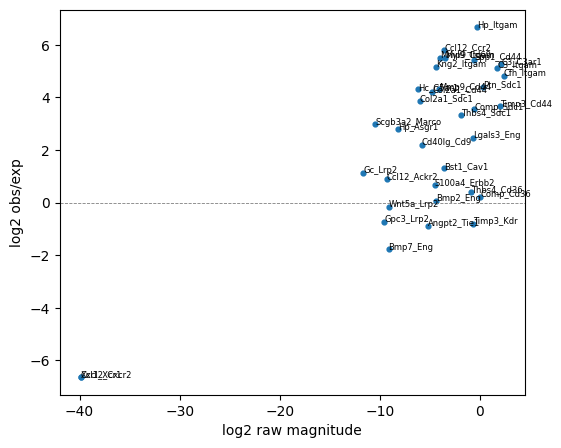

In [327]:
# Siome diagnostic on the pairs 
Sr, Sm = lr_score(adata_, ts, tr, groups, 'raw'), lr_score(adata_, ts, tr, groups, 'mean')
d = np.log2(Sm.replace(0, np.nan)) - np.log2(Sr.replace(0, np.nan)); print(d.std().max(), d.mean().head())
E, M = lr_log(lr_aggregate(adata_, Sm, ts, by='time')), np.log2(lr_aggregate(adata_, Sr, ts, by='time').clip(lower=1e-12))
fig, ax = get_figs(1, 6, 5); ax.scatter(M.loc['cryo7D'], E.loc['cryo7D'], s=12)
[ax.annotate(g, (M.loc['cryo7D', g], E.loc['cryo7D', g]), fontsize=6) for g in E.columns]
ax.axhline(0, ls='--', lw=.6, c='grey'); ax.set(xlabel='log2 raw magnitude', ylabel='log2 obs/exp')